In [5]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

In [6]:
s = make_array(1, 5, 7, 3, 9)
s

array([1, 5, 7, 3, 9])

In [7]:
val = percentile(0, s)
val

1

# Estimation

In [8]:
population = Table.read_table('san_francisco_2019.csv')
population.show(5)

Organization Group,Department,Job Family,Job,Salary,Overtime,Benefits,Total Compensation
Public Protection,Adult Probation,Information Systems,IS Trainer-Journey,91332,0,40059,131391
Public Protection,Adult Probation,Information Systems,IS Engineer-Assistant,123241,0,49279,172520
Public Protection,Adult Probation,Information Systems,IS Business Analyst-Senior,115715,0,46752,162468
Public Protection,Adult Probation,Information Systems,IS Business Analyst-Principal,159394,0,57312,216706
Public Protection,Adult Probation,Information Systems,IS Programmer Analyst,70035,0,28671,98706


In [9]:
population.sort('Total Compensation', descending=True).show(5)

Organization Group,Department,Job Family,Job,Salary,Overtime,Benefits,Total Compensation
General Administration & Finance,Retirement Services,Administrative & Mgmt (Unrep),Chief Investment Officer,577633,0,146398,724031
General Administration & Finance,Retirement Services,Unassigned,Managing Director,483072,0,134879,617951
General Administration & Finance,Retirement Services,Unassigned,Managing Director,482649,0,134905,617554
General Administration & Finance,Retirement Services,Unassigned,Managing Director,451507,0,120276,571784
General Administration & Finance,Retirement Services,Unassigned,Managing Director,449378,0,120857,570235


In [10]:
population.sort('Total Compensation', descending=False).show(5)

Organization Group,Department,Job Family,Job,Salary,Overtime,Benefits,Total Compensation
Public Protection,Adult Probation,Probation & Parole,Deputy Probation Officer,0,0,0,0
Public Protection,Fire Department,"Clerical, Secretarial & Steno",Senior Clerk Typist,0,0,0,0
Public Protection,Juvenile Court,Correction & Detention,"Counselor, Juvenile Hall PERS",0,0,0,0
Public Protection,Police,"Clerical, Secretarial & Steno",Clerk Typist,0,0,0,0
Public Protection,Sheriff,Correction & Detention,Deputy Sheriff,0,0,0,0


Let's capture the data for folks who make above a certain salary:
    - $15/hr, 20hr/wk, 50 weeks

In [11]:
min_salary = 15 * 20 * 50
min_salary

15000

In [12]:
population = population.where('Salary', are.above(min_salary))
population

Organization Group,Department,Job Family,Job,Salary,Overtime,Benefits,Total Compensation
Public Protection,Adult Probation,Information Systems,IS Trainer-Journey,91332,0,40059,131391
Public Protection,Adult Probation,Information Systems,IS Engineer-Assistant,123241,0,49279,172520
Public Protection,Adult Probation,Information Systems,IS Business Analyst-Senior,115715,0,46752,162468
Public Protection,Adult Probation,Information Systems,IS Business Analyst-Principal,159394,0,57312,216706
Public Protection,Adult Probation,Information Systems,IS Programmer Analyst,70035,0,28671,98706
Public Protection,Adult Probation,Information Systems,IS Project Director,175742,0,60830,236572
Public Protection,Adult Probation,Information Systems,IT Operations Support Admin IV,123840,0,49429,173269
Public Protection,Adult Probation,"Payroll, Billing & Accounting",Accountant III,111816,0,46319,158135
Public Protection,Adult Probation,"Budget, Admn & Stats Analysis",Statistician,87725,0,38899,126624
Public Protection,Adult Probation,"Budget, Admn & Stats Analysis",Senior Administrative Analyst,116192,0,47651,163843


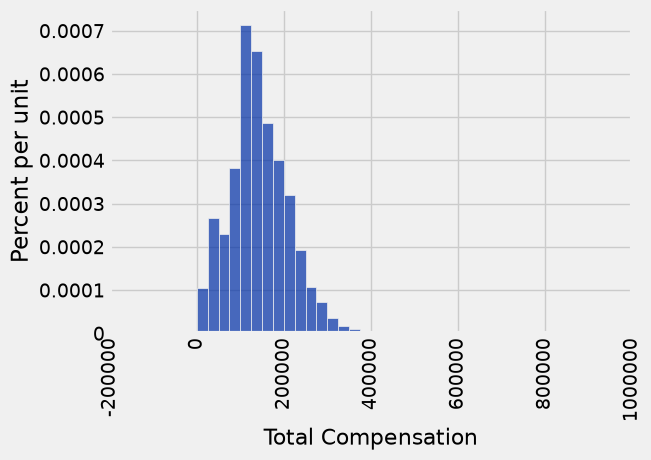

In [13]:
population.hist('Total Compensation', bins=np.arange(0, 800000, 25000))

## Can we calculate a population parameter?
    - Population parameter: The median total compensation of all employees

In [14]:
pop_median = percentile(50, population.column('Total Compensation'))
pop_median

135747.0

In [15]:
population.num_rows

37103

## Create an estimate for the median of compensation
    - Take a sample

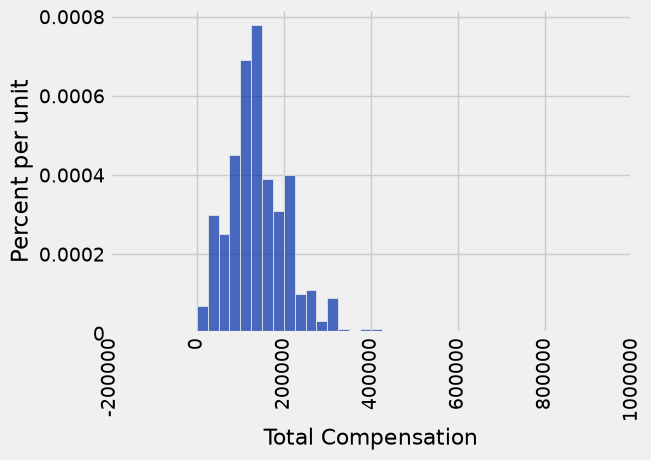

In [16]:
sample_size = 400
a_sample = population.sample(sample_size, with_replacement=False)
a_sample.hist('Total Compensation', bins = np.arange(0, 800000, 25000))

In [17]:
sample_median = percentile(50, a_sample.column('Total Compensation'))
sample_median

132718.0

## We could take repeated samples from the population to express the variability of the estimate.
    - This would not be possible in real life because of time and cost.

In [18]:
repeat_sample_medians = make_array()
num_resamples = 1000

for i in np.arange(num_resamples):
    r_sample = population.sample(sample_size, with_replacement=False)
    r_sample_median = percentile(50, r_sample.column('Total Compensation'))
    repeat_sample_medians = np.append(repeat_sample_medians, r_sample_median)

repeat_sample_medians

array([ 129243.,  130826.,  135577.,  132825.,  136932.,  135861.,
        136783.,  137039.,  136876.,  134385.,  132710.,  129887.,
        140653.,  128880.,  137944.,  134729.,  134393.,  142223.,
        140873.,  132182.,  133169.,  136445.,  140287.,  132703.,
        133381.,  136326.,  134894.,  141567.,  133669.,  130498.,
        136763.,  133717.,  135601.,  136910.,  128844.,  137850.,
        140112.,  125122.,  133810.,  137833.,  138452.,  135936.,
        129524.,  139851.,  134821.,  139988.,  135400.,  139337.,
        137177.,  133928.,  134368.,  136486.,  135414.,  134251.,
        136027.,  130788.,  140141.,  138718.,  135977.,  132202.,
        132245.,  135601.,  135087.,  127850.,  136522.,  139975.,
        130452.,  144741.,  131544.,  132938.,  142159.,  132463.,
        132926.,  135059.,  135511.,  132944.,  133302.,  139342.,
        140823.,  140941.,  140148.,  131747.,  131560.,  134184.,
        130898.,  139170.,  133878.,  132902.,  137321.,  1402

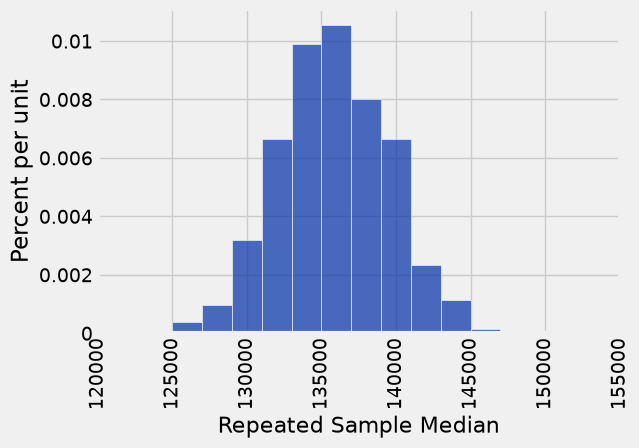

In [19]:
repeat_table = Table().with_column('Repeated Sample Median', repeat_sample_medians)
repeat_table.hist(bins = np.arange(125000, 155000, 2000))

## Bootstrap: Resample from the sample

In [20]:
def one_bootstrap_median():
    bt_sample = a_sample.sample(a_sample.num_rows, with_replacement=True)
    return percentile(50, bt_sample.column('Total Compensation'))

In [21]:
bt_sample_medians = make_array()
num_resamples = 1000

for i in np.arange(num_resamples):
    new_median = one_bootstrap_median()
    bt_sample_medians = np.append(bt_sample_medians, new_median)

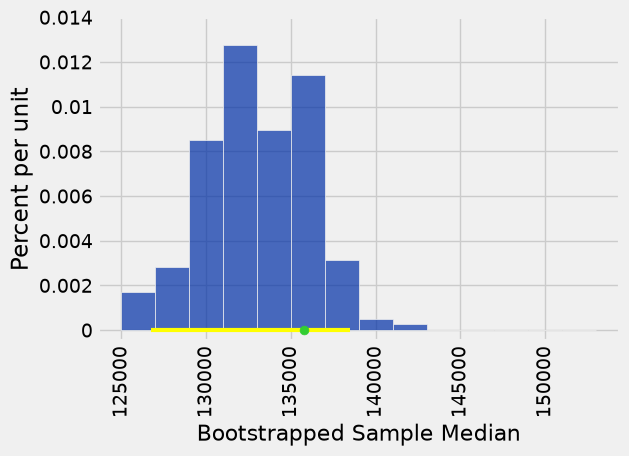

In [22]:
bt_sample_table = Table().with_column('Bootstrapped Sample Median', bt_sample_medians)
bt_sample_table.hist(bins = np.arange(125000, 155000, 2000))

left = percentile(2.5, bt_sample_medians)
right = percentile(97.5, bt_sample_medians)

#Plotting the population median
parameter_green = '#32CD32'
plt.ylim(-0.000005, 0.00014)
plt.plot(make_array(left, right), make_array(0,0), color='yellow', lw=3, zorder=1)
plt.scatter(pop_median, 0, color=parameter_green, s=40)

## What does X% confidence mean?

In [75]:
def confidence_interval_95_display(sample_size):
    original_sample = population.sample(sample_size, with_replacement=False)

    bootstrap_stats = make_array()
    for i in np.arange(1000):
        next_bs_sample = original_sample.sample(original_sample.num_rows, with_replacement=True)
        bootstrap_stats = np.append(bootstrap_stats,
                                    percentile(50, next_bs_sample.column('Total Compensation')))
    left = percentile(2.5, bootstrap_stats)
    right = percentile(97.5, bootstrap_stats)
    return make_array(left, right)

In [76]:
confidence_interval_95_display(2)

array([ 124199.,  217880.])

In [78]:
intervals = Table(['lower', 'upper'])

for i in np.arange(100):
    interval = confidence_interval_95_display(100)
    intervals = intervals.with_row([interval.item(0), interval.item(1)])

intervals = intervals.with_columns('Number', np.arange(100) + 1)

In [79]:
intervals.show(5)

lower,upper,Number
115162,142180,1
122500,151486,2
123452,167289,3
123483,158089,4
121171,141995,5


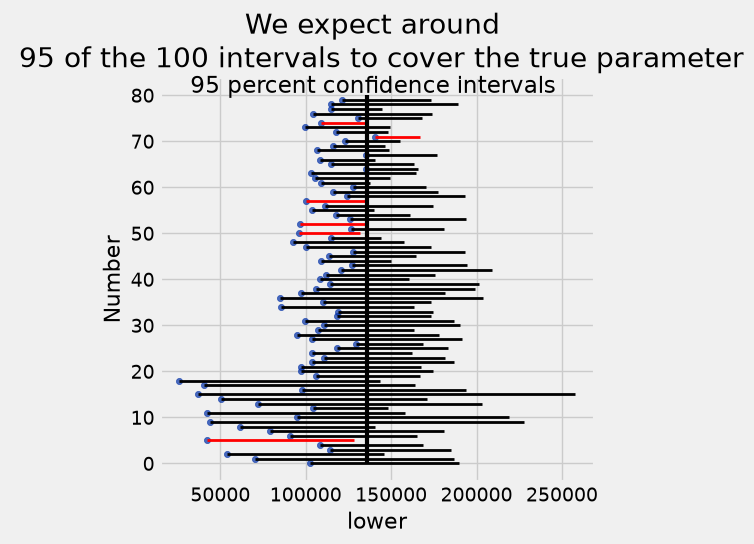

In [83]:
intervals.scatter('lower', 'Number')
truth = pop_median
for row in intervals.rows:
    if row.item('lower') > truth or row.item('upper') < truth:
        color = 'red'
    else:
        color = 'black'
    plt.plot((row.item('lower'), row.item('upper')),
             (row.item('Number'), row.item('Number')),
             color, lw=2)
plt.plot((truth, truth), (0, intervals.num_rows), color='black', lw=3);
plt.suptitle('\n \n 95 percent confidence intervals', y=1)
plt.title('We expect around \n 95 of the 100 intervals to cover the true parameter');

## How does sample size effect the confidence interval

In [84]:
intervals = Table(['Number', 'lower', 'upper', 'sample_size'])

for n in [10, 20, 30, 50]:
    for k in np.arange(intervals.num_rows, intervals.num_rows + 20):
        interval = confidence_interval_95_display(n)
        intervals = intervals.with_row([k, interval.item(0), interval.item(1), n])

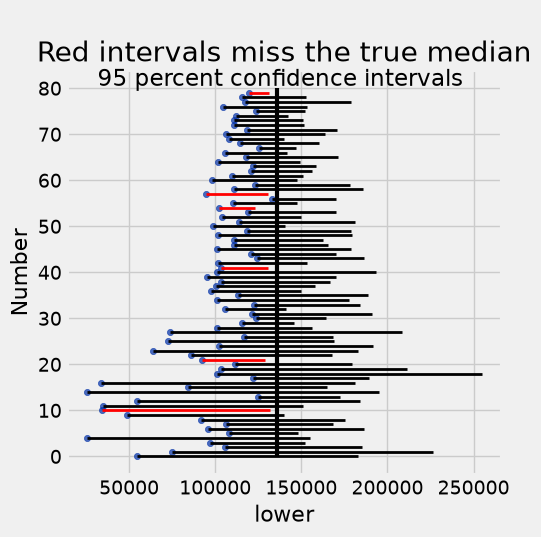

In [85]:
intervals.scatter('lower', 'Number')
truth = pop_median
for row in intervals.rows:
    if row.item('lower') > truth or row.item('upper') < truth:
        color = 'red'
    else:
        color = 'black'
    plt.plot((row.item('lower'), row.item('upper')),
             (row.item('Number'), row.item('Number')),
             color, lw=2)
plt.plot((truth, truth), (0, intervals.num_rows), color='black', lw=3);
plt.suptitle('\n \n 95 percent confidence intervals', y=1)
plt.title('Red intervals miss the true median');